## CLIP

Paper: Learning Transferable Visual Models From Natural Language Supervision
(https://arxiv.org/abs/2103.00020)

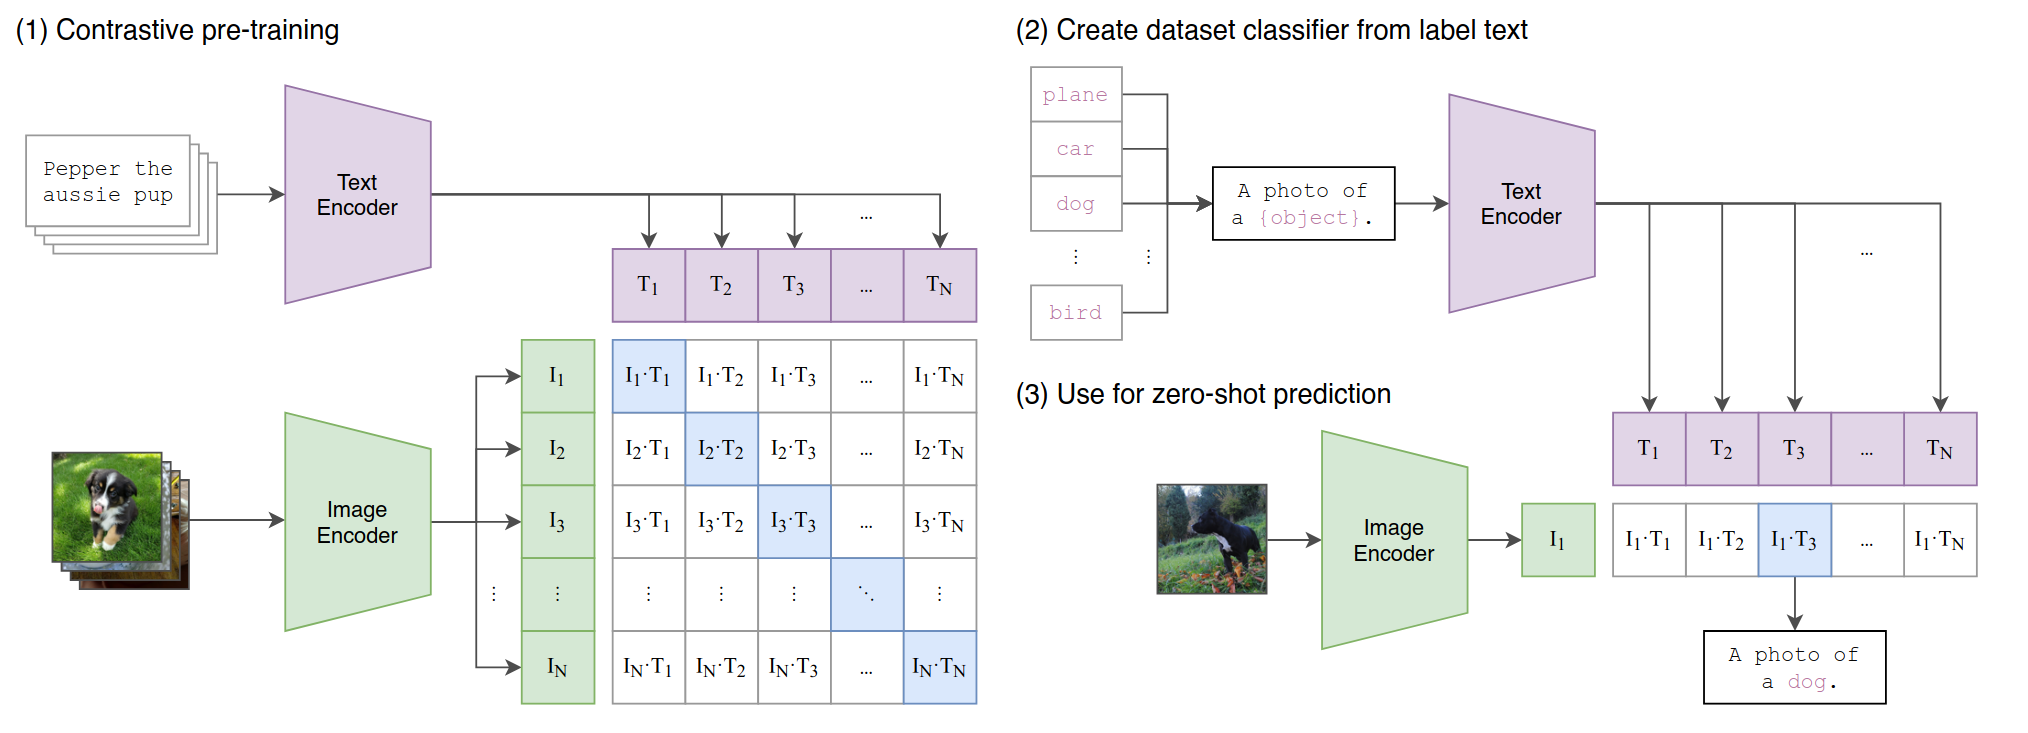

### Prepare Model

In [ ]:
import torch 
import torch.nn as nn

In [ ]:
from encoder import TextEncoder
def textencoder_unittest():
    text_encoder=TextEncoder()
    x=torch.tensor([1,2,3,4,5,6,7,8,9,0])
    y=text_encoder(x)
    print(y.shape)

textencoder_unittest()

torch.Size([10, 8])


In [ ]:
from encoder import ImageEncoder
def imageencoder_unittest():
    img_encoder=ImageEncoder()
    out=img_encoder(torch.randn(2,1,28,28))
    print(out.shape)

imageencoder_unittest()

torch.Size([2, 8])


In [ ]:
from clip import CLIP

### Prepare Datasets

In [6]:
from torchvision import datasets, transforms

transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))])
train_data = datasets.MNIST(root="./data/", transform=transform, train=True, download=True)
test_data = datasets.MNIST(root="./data/", transform=transform, train=False)
print(train_data[0][0].shape)

torch.Size([1, 28, 28])


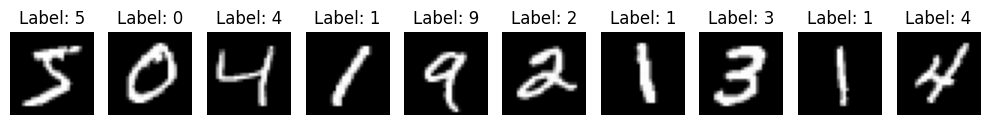

In [7]:
import matplotlib.pyplot as plt

# 遍历前10张图片
fig, axes = plt.subplots(1, 10, figsize=(10, 2))  # 1行10列的子图
for i in range(10):
    image, label = train_data[i]
    ax = axes[i]  # 获取当前子图
    ax.imshow(image[0], cmap='gray')  # 显示灰度图
    ax.set_title(f'Label: {label}')  # 显示标签
    ax.axis('off')  # 关闭坐标轴

plt.tight_layout()  # 自动调整子图间的间距
plt.show()

## Train it!

In [ ]:
from torch.utils.data import DataLoader
from tqdm import tqdm

from utils import EMALoss

num_epoch = 20
batch_size = 1024
lr = 5e-4
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
clip = CLIP().to(device) # suit MNIST only

dataloader = DataLoader(train_data, batch_size=batch_size)
optimizer = torch.optim.Adam(clip.parameters(), lr=lr)
ema_loss = EMALoss(alpha=0.9) # for display only

with tqdm(total=len(dataloader)*num_epoch) as pbar:
    for epoch in range(num_epoch):
        pbar.set_description(f'Epoch {epoch}')
        ema_loss.reset()
        clip.train()
        for imgs, labels in dataloader:
            imgs, labels = imgs.to(device), labels.to(device)
            loss = clip.get_loss(imgs, labels)
                
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            ema_loss.update(loss)
            pbar.set_postfix(loss=f'{ema_loss.item():.4f}')
            pbar.update(1)

        # if (epoch + 1) % (num_epoch // 5) == 0:
        #     vqvae.eval()
        #     with torch.no_grad():
        #         x_, *_ = vqvae(all_classes)
        #         sample.append(x_)

torch.save(clip, 'weights/clip_resnet_mnist.pt')

Epoch 19: 100%|████████████████| 1180/1180 [02:30<00:00,  7.85it/s, loss=4.3558]


In [ ]:
clip.make_vector_db(test_data, 'weights/mnist_db.pt')

/tmp/ipykernel_5940/88775198.py:3: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  clip = torch.load('test.pt')
100%|███████████████████████████████████████████| 10/10 [00:01<

In [ ]:
from clip import Retriever

## Demo

In [ ]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
# load clip model and database
clip = torch.load('weights/clip_resnet_mnist.pt', device=device)
retriever = Retriever('weights/mnist_db.pt', clip, device)

/tmp/ipykernel_5940/2321558264.py:3: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  db = torch.load(db_file)


### 🔍Text-to-Image Retrieval

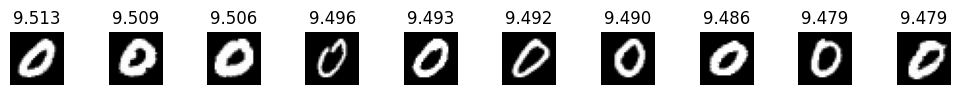

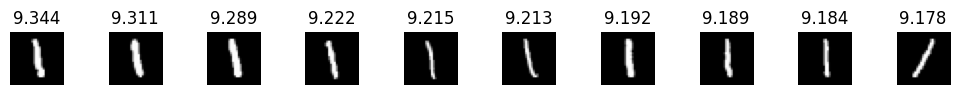

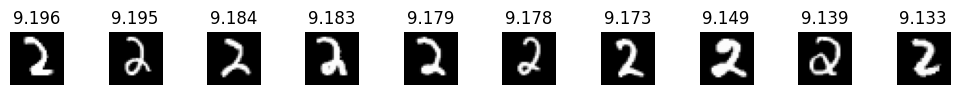

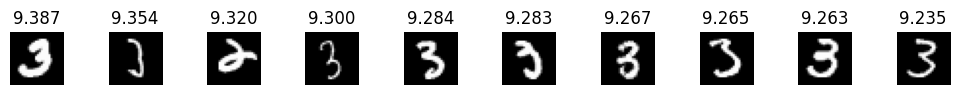

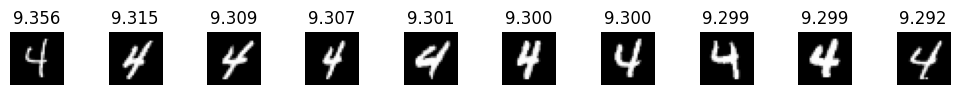

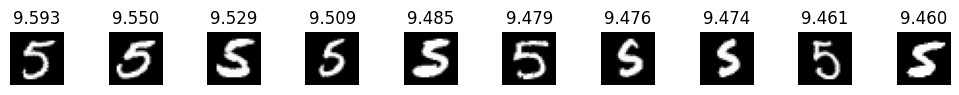

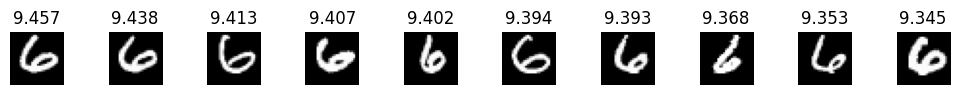

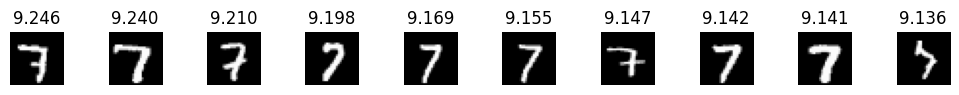

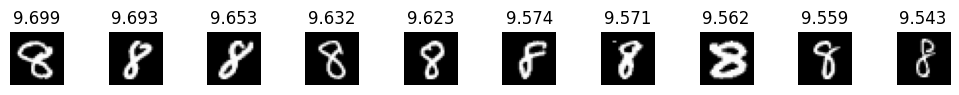

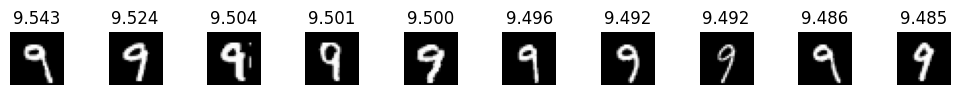

In [ ]:
def text2img(label:int):
    assert 0 <= label < 10
    similarities, imgs = retriever.text2img(torch.tensor([label]), k=10)
    # print(imgs.shape, similarities.shape)
    fig, axes = plt.subplots(1, len(imgs), figsize=(len(imgs), 1))  # 1 row, 10 cols
    for i in range(len(imgs)):
        ax = axes[i]
        label, img = i, imgs[i].cpu()
        ax.imshow(img[0], cmap='gray')
        ax.set_title(f'{similarities[i]:.3f}')
        ax.axis('off')
    plt.tight_layout()
    plt.show()

for i in range(10):
    text2img(i)

### 🔍Image-to-Image Retrieval

Ground Truth


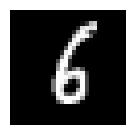

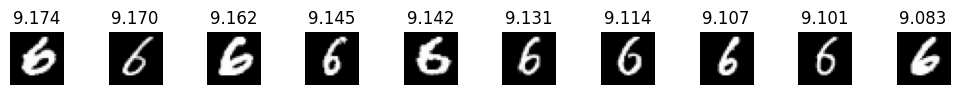

In [ ]:
import random
def img2img():
    print('Ground Truth')
    ###
    img, _ = random.choice(test_data)
    similarities, imgs = retriever.img2img(img.unsqueeze(0), k=10)
    fig, ax = plt.subplots(figsize=(1.5, 1.5))
    ax.imshow(img[0], cmap='gray')
    ax.axis('off')
    plt.show()
    
    fig, axes = plt.subplots(1, len(imgs), figsize=(len(imgs), 1))  # 1 row, 10 cols
    for i in range(len(imgs)):
        ax = axes[i]
        label, img = i, imgs[i].cpu()
        ax.imshow(img[0], cmap='gray')
        ax.set_title(f'{similarities[i]:.3f}')
        ax.axis('off')
    plt.tight_layout()
    plt.show()

img2img()